In [ ]:
%pip -q install imbalanced-learn openpyxl

## 1. Imports and reproducibility

In [ ]:
import os
import sys
import json
import time
import platform
import warnings
import zipfile
from pathlib import Path
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    AdaBoostClassifier, GradientBoostingClassifier
)
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, auc, make_scorer
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV,
    cross_validate, cross_val_score
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from scipy.stats import binomtest

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

## 2. Upload and load the official dataset
.

In [ ]:
DATA_PATH = None

try:
    from google.colab import files
    uploaded = files.upload()
    excel_files = [name for name in uploaded.keys()
                   if name.lower().endswith((".xlsx", ".xls"))]
    if not excel_files:
        raise FileNotFoundError(
            "No Excel workbook was uploaded. Upload Dry_Bean_Dataset.xlsx."
        )
    DATA_PATH = excel_files[0]
except ImportError:
    possible_files = [
        "Dry_Bean_Dataset.xlsx",
        "/mnt/data/Dry_Bean_Dataset.xlsx"
    ]
    for candidate in possible_files:
        if os.path.exists(candidate):
            DATA_PATH = candidate
            break
    if DATA_PATH is None:
        raise FileNotFoundError(
            "Place Dry_Bean_Dataset.xlsx in the notebook folder."
        )

xls = pd.ExcelFile(DATA_PATH)
print("Workbook:", DATA_PATH)
print("Sheets:", xls.sheet_names)

df = None
for sheet in xls.sheet_names:
    candidate = pd.read_excel(DATA_PATH, sheet_name=sheet)
    if "Class" in candidate.columns:
        df = candidate
        print("Loaded sheet:", sheet)
        break

if df is None:
    raise ValueError("Could not find a worksheet containing the target column 'Class'.")

print("Original dataset shape:", df.shape)
display(df.head())

Saving Dry_Bean_Dataset.xlsx to Dry_Bean_Dataset.xlsx
Workbook: Dry_Bean_Dataset.xlsx
Sheets: ['Dry_Beans_Dataset', 'Citation_Request']
Loaded sheet: Dry_Beans_Dataset
Original dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Dataset validation and cleaning


In [ ]:
if "Class" not in df.columns:
    raise ValueError("Target column 'Class' is missing.")

original_rows = len(df)
duplicate_count = int(df.duplicated().sum())
missing_total = int(df.isna().sum().sum())
infinite_count = int(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

df_clean = df.drop_duplicates().reset_index(drop=True).copy()
removed_duplicates = original_rows - len(df_clean)

print(f"Original rows: {original_rows:,}")
print(f"Exact duplicate rows removed: {removed_duplicates:,}")
print(f"Rows after duplicate removal: {len(df_clean):,}")
print(f"Missing cells before cleaning: {missing_total:,}")
print(f"Infinite numeric values before cleaning: {infinite_count:,}")
print("Remaining duplicate rows:", int(df_clean.duplicated().sum()))

if df_clean["Class"].isna().any():
    raise ValueError("Target column contains missing labels; investigate before training.")

display(df_clean.dtypes.to_frame("dtype"))
display(df_clean["Class"].value_counts().rename_axis("Class").to_frame("samples"))

Original rows: 13,611
Exact duplicate rows removed: 68
Rows after duplicate removal: 13,543
Missing cells before cleaning: 0
Infinite numeric values before cleaning: 0
Remaining duplicate rows: 0


,dtype
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64


,samples
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1860
CALI,1630
BARBUNYA,1322
BOMBAY,522


## 4. Exploratory Data Analysis (EDA)



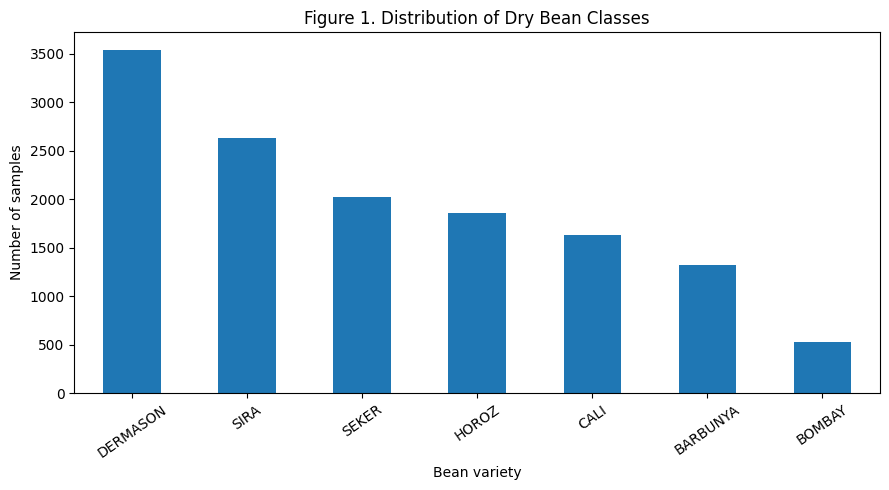

,samples,percentage
Class,,
DERMASON,3546,26.18
SIRA,2636,19.46
SEKER,2027,14.97
HOROZ,1860,13.73
CALI,1630,12.04
BARBUNYA,1322,9.76
BOMBAY,522,3.85


Largest/smallest class ratio: 6.79


In [ ]:
RESULTS_DIR = Path("dry_bean_results")
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
MODEL_DIR = RESULTS_DIR / "models"

for folder in [FIG_DIR, TABLE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

target_counts = df_clean["Class"].value_counts()
target_percent = (target_counts / target_counts.sum() * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 5))
target_counts.plot(kind="bar", ax=ax)
ax.set_title("Figure 1. Distribution of Dry Bean Classes")
ax.set_xlabel("Bean variety")
ax.set_ylabel("Number of samples")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(FIG_DIR / "figure1_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

display(pd.DataFrame({"samples": target_counts, "percentage": target_percent}))
print("Largest/smallest class ratio:",
      round(target_counts.max() / target_counts.min(), 2))

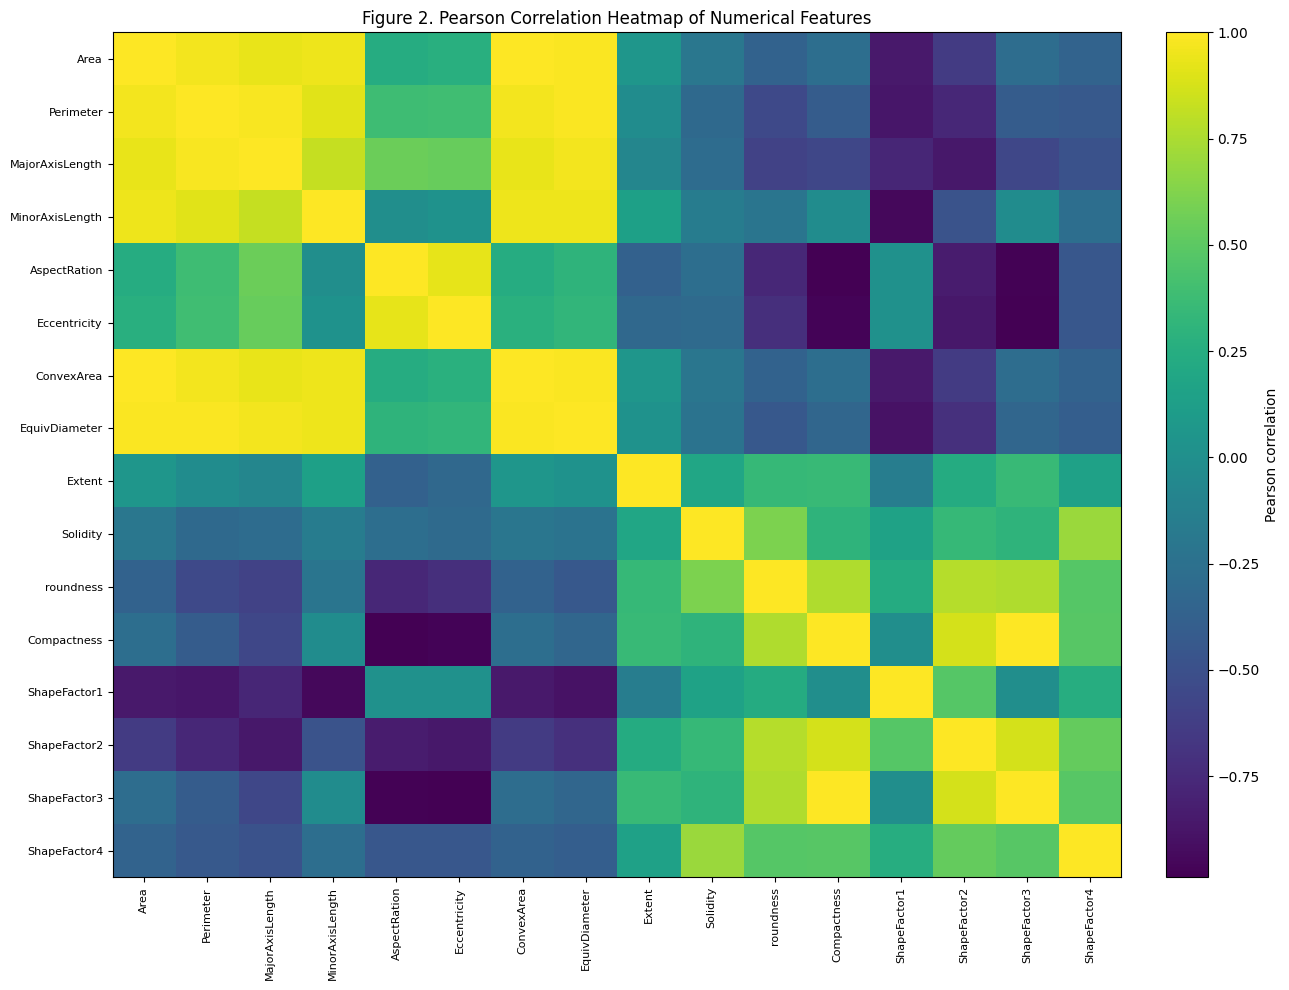

Top absolute feature correlations:


,,absolute_correlation
Area,ConvexArea,0.999940
Compactness,ShapeFactor3,0.998684
Perimeter,EquivDiameter,0.991453
AspectRation,Compactness,0.987644
ConvexArea,EquivDiameter,0.985255
Area,EquivDiameter,0.984998
Eccentricity,ShapeFactor3,0.981058
AspectRation,ShapeFactor3,0.978528
Perimeter,MajorAxisLength,0.977561
Eccentricity,Compactness,0.970308


In [ ]:
feature_cols = [c for c in df_clean.columns if c != "Class"]
numeric_cols = df_clean[feature_cols].select_dtypes(include=np.number).columns.tolist()

if len(numeric_cols) < 8:
    raise ValueError(f"Expected at least 8 numeric features; found {len(numeric_cols)}.")

corr = df_clean[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
im = ax.imshow(corr.values, aspect="auto")
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=90, fontsize=8)
ax.set_yticklabels(numeric_cols, fontsize=8)
ax.set_title("Figure 2. Pearson Correlation Heatmap of Numerical Features")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure2_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
top_corr = upper.stack().abs().sort_values(ascending=False).head(10)
print("Top absolute feature correlations:")
display(top_corr.rename("absolute_correlation").to_frame())

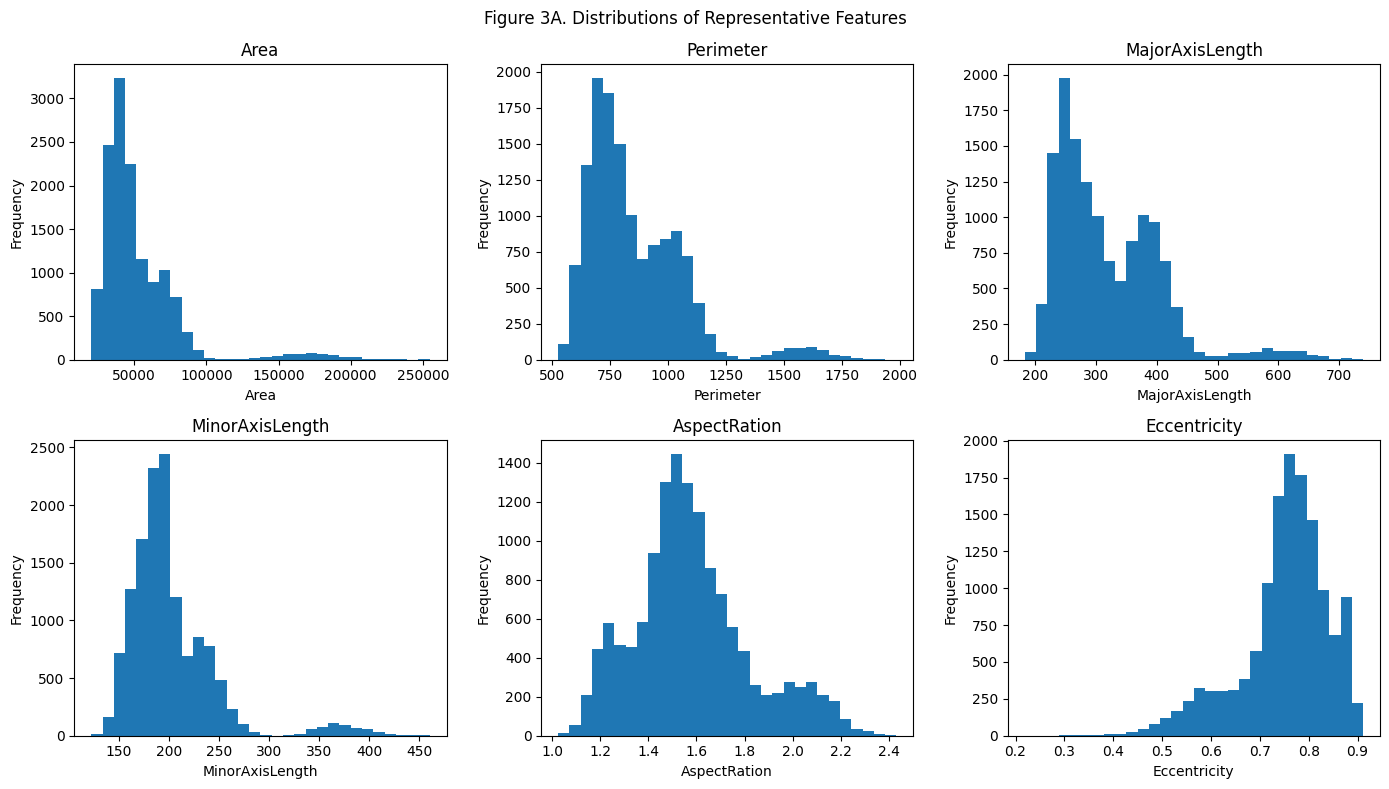

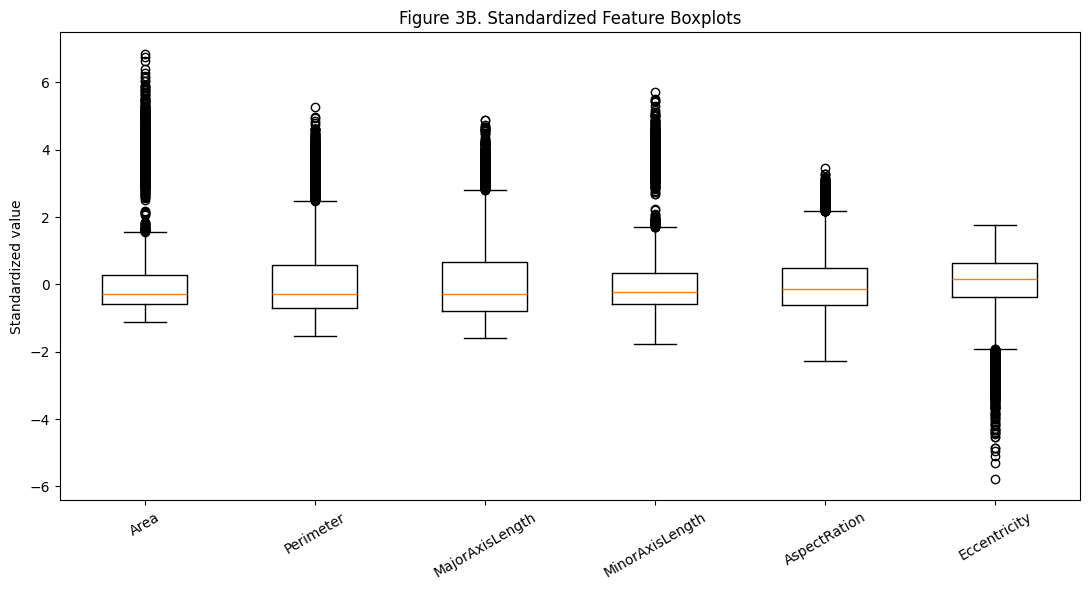

,feature,IQR_outlier_count
5,Eccentricity,833
9,Solidity,774
15,ShapeFactor4,760
3,MinorAxisLength,567
0,Area,551
6,ConvexArea,549
12,ShapeFactor1,533
7,EquivDiameter,526
1,Perimeter,500
4,AspectRation,485


IQR outliers are flagged for inspection; they are not automatically deleted.


In [ ]:
# Figure 3A: histograms for six representative numerical features.
selected_for_hist = numeric_cols[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), selected_for_hist):
    ax.hist(df_clean[col].dropna(), bins=30)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
fig.suptitle("Figure 3A. Distributions of Representative Features")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure3a_feature_histograms.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 3B: boxplots for the same features after standardization for visual comparison.
plot_data = StandardScaler().fit_transform(df_clean[selected_for_hist])
fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot(plot_data, labels=selected_for_hist, showfliers=True)
ax.set_title("Figure 3B. Standardized Feature Boxplots")
ax.set_ylabel("Standardized value")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG_DIR / "figure3b_feature_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

iqr_rows = []
for col in numeric_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df_clean[col] < lower) | (df_clean[col] > upper_bound)).sum())
    iqr_rows.append({"feature": col, "IQR_outlier_count": count})
display(pd.DataFrame(iqr_rows).sort_values("IQR_outlier_count", ascending=False))
print("IQR outliers are flagged for inspection; they are not automatically deleted.")

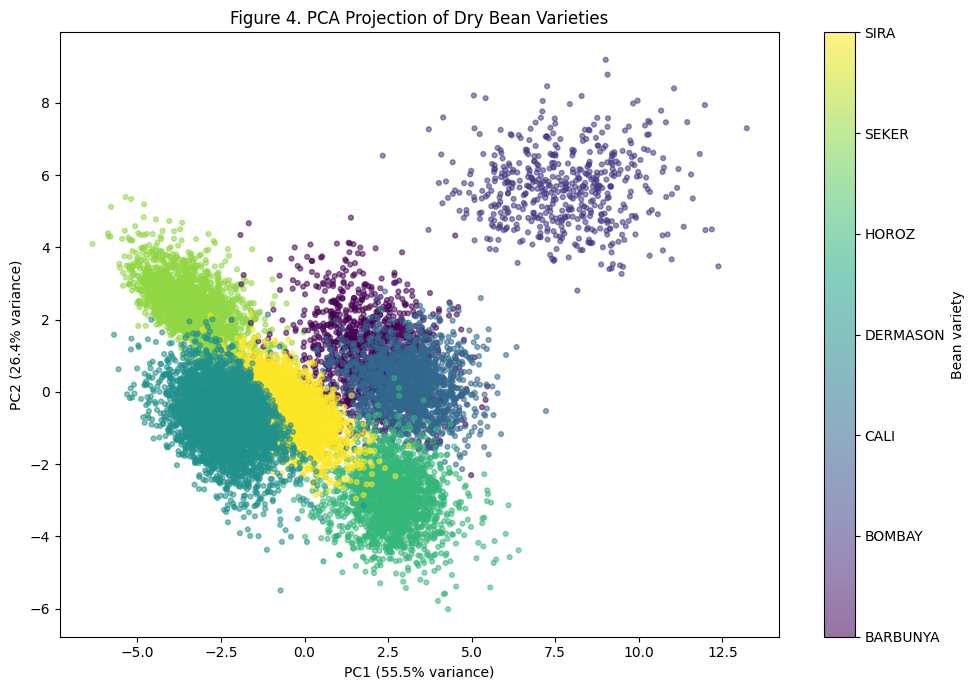

Variance explained by PC1 and PC2: 81.91 %


In [ ]:
from sklearn.decomposition import PCA

X_eda = df_clean[numeric_cols].copy()
y_eda = df_clean["Class"].astype(str).copy()

X_eda_scaled = StandardScaler().fit_transform(X_eda)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_eda_scaled)

class_names = sorted(y_eda.unique())
class_to_code = {name: idx for idx, name in enumerate(class_names)}
y_codes = y_eda.map(class_to_code).to_numpy()

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=y_codes, alpha=0.55, s=12)
ax.set_title("Figure 4. PCA Projection of Dry Bean Varieties")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
cbar = fig.colorbar(scatter, ax=ax, ticks=range(len(class_names)))
cbar.ax.set_yticklabels(class_names)
cbar.set_label("Bean variety")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure4_pca_projection.png", dpi=300, bbox_inches="tight")
plt.show()

print("Variance explained by PC1 and PC2:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

### Automatically generated EDA observations



In [ ]:
print("EDA SUMMARY")
print("-" * 60)
print(f"Rows after exact-duplicate removal: {len(df_clean):,}")
print(f"Numerical predictors: {len(numeric_cols)}")
print(f"Number of classes: {df_clean['Class'].nunique()}")
print(f"Missing values after duplicate removal: {int(df_clean.isna().sum().sum())}")
print(f"Minority class: {target_counts.idxmin()} ({target_counts.min()} samples after duplicate removal)")
print(f"Majority class: {target_counts.idxmax()} ({target_counts.max()} samples after duplicate removal)")
print(f"Majority/minority ratio after duplicate removal: {target_counts.max()/target_counts.min():.2f}")
print(f"First two PCA components explain {pca.explained_variance_ratio_.sum()*100:.2f}% variance.")

EDA SUMMARY
------------------------------------------------------------
Rows after exact-duplicate removal: 13,543
Numerical predictors: 16
Number of classes: 7
Missing values after duplicate removal: 0
Minority class: BOMBAY (522 samples after duplicate removal)
Majority class: DERMASON (3546 samples after duplicate removal)
Majority/minority ratio after duplicate removal: 6.79
First two PCA components explain 81.91% variance.


## 5. Define target, predictors and stratified train/test split



In [ ]:
X = df_clean[numeric_cols].copy()
y = df_clean["Class"].astype(str).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

classes = np.array(sorted(y_train.unique()))
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training class distribution:")
display(y_train.value_counts().rename_axis("Class").to_frame("samples"))
print("Test class distribution:")
display(y_test.value_counts().rename_axis("Class").to_frame("samples"))

Training shape: (10834, 16)
Test shape: (2709, 16)
Training class distribution:


,samples
Class,
DERMASON,2837
SIRA,2109
SEKER,1621
HOROZ,1488
CALI,1304
BARBUNYA,1057
BOMBAY,418


Test class distribution:


,samples
Class,
DERMASON,709
SIRA,527
SEKER,406
HOROZ,372
CALI,326
BARBUNYA,265
BOMBAY,104


## 6. Imbalance handling and leakage-safe pipeline design



In [ ]:
MI_SCORE_FUNC = partial(
    mutual_info_classif,
    random_state=RANDOM_STATE,
    discrete_features=False
)

CV_SPLITS = 5
N_ITER = 3  # Compact search; increase only if runtime permits.
N_JOBS = -1

cv = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "precision_weighted": "precision_weighted",
    "recall_macro": "recall_macro",
    "recall_weighted": "recall_weighted",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
    "balanced_accuracy": "balanced_accuracy",
    "mcc": make_scorer(matthews_corrcoef)
}

def build_pipeline(estimator, use_smote):
    sampler = (
        SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
        if use_smote else "passthrough"
    )
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=MI_SCORE_FUNC, k=12)),
        ("sampler", sampler),
        ("model", estimator)
    ])

print("CV folds:", CV_SPLITS)
print("Randomized search candidates per model:", N_ITER)
print("Scoring used to select hyperparameters: macro-F1")

CV folds: 5
Randomized search candidates per model: 3
Scoring used to select hyperparameters: macro-F1


## 7. Define baseline and ten classifiers

- Linear: Logistic Regression
- Distance-based: KNN
- Probabilistic: Gaussian Naive Bayes
- Kernel: RBF SVM
- Tree/ensemble: Decision Tree, Random Forest, Extra Trees, AdaBoost, Gradient Boosting
- Neural: Multi-Layer Perceptron

In [ ]:
MODEL_CONFIGS = {
    "Logistic Regression": {
        "family": "Linear",
        "estimator": LogisticRegression(
            max_iter=2500, class_weight="balanced",
            solver="lbfgs", random_state=RANDOM_STATE
        ),
        "use_smote": False,
        "params": {
            "model__C": [0.1, 1.0, 10.0],
            "select__k": [8, 12, 16]
        }
    },
    "K-Nearest Neighbors": {
        "family": "Distance-based",
        "estimator": KNeighborsClassifier(),
        "use_smote": True,
        "params": {
            "model__n_neighbors": [5, 7, 9, 11],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
            "select__k": [8, 12, 16]
        }
    },
    "Gaussian Naive Bayes": {
        "family": "Probabilistic",
        "estimator": GaussianNB(),
        "use_smote": True,
        "params": {
            "model__var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7],
            "select__k": [8, 12, 16]
        }
    },
    "SVM (RBF)": {
        "family": "Kernel",
        "estimator": SVC(
            kernel="rbf", probability=True,
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "use_smote": False,
        "params": {
            "model__C": [0.5, 1.0, 5.0, 10.0],
            "model__gamma": ["scale", "auto"],
            "select__k": [8, 12, 16]
        }
    },
    "Decision Tree": {
        "family": "Tree & ensemble",
        "estimator": DecisionTreeClassifier(
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "use_smote": False,
        "params": {
            "model__max_depth": [None, 10, 20, 30],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "select__k": [8, 12, 16]
        }
    },
    "Random Forest": {
        "family": "Tree & ensemble",
        "estimator": RandomForestClassifier(
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=1
        ),
        "use_smote": False,
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 20],
            "model__min_samples_leaf": [1, 2],
            "model__max_features": ["sqrt", 0.8],
            "select__k": [8, 12, 16]
        }
    },
    "Extra Trees": {
        "family": "Tree & ensemble",
        "estimator": ExtraTreesClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=1
        ),
        "use_smote": False,
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 20],
            "model__min_samples_leaf": [1, 2],
            "model__max_features": ["sqrt", 0.8],
            "select__k": [8, 12, 16]
        }
    },
    "AdaBoost": {
        "family": "Tree & ensemble",
        "estimator": AdaBoostClassifier(random_state=RANDOM_STATE),
        "use_smote": True,
        "params": {
            "model__n_estimators": [50, 100, 150],
            "model__learning_rate": [0.5, 1.0],
            "select__k": [8, 12, 16]
        }
    },
    "Gradient Boosting": {
        "family": "Tree & ensemble",
        "estimator": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "use_smote": True,
        "params": {
            "model__n_estimators": [50, 75, 100],
            "model__learning_rate": [0.05, 0.1],
            "model__max_depth": [2, 3],
            "model__subsample": [0.8, 1.0],
            "select__k": [8, 12, 16]
        }
    },
    "Multi-Layer Perceptron": {
        "family": "Neural",
        "estimator": MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=300,
            early_stopping=False,
            random_state=RANDOM_STATE
        ),
        "use_smote": True,
        "params": {
            "model__hidden_layer_sizes": [(64,), (100,), (100, 50)],
            "model__alpha": [0.0001, 0.001],
            "model__learning_rate_init": [0.001, 0.005],
            "select__k": [8, 12, 16]
        }
    }
}

print("Number of substantive models:", len(MODEL_CONFIGS))
print("Families represented:", sorted(set(v["family"] for v in MODEL_CONFIGS.values())))

Number of substantive models: 10
Families represented: ['Distance-based', 'Kernel', 'Linear', 'Neural', 'Probabilistic', 'Tree & ensemble']


## 8. Train and tune all ten models



In [ ]:
fitted_models = {}
search_objects = {}
result_rows = []
best_params_dict = {}

for model_name, config in MODEL_CONFIGS.items():
    print("\n" + "=" * 80)
    print("TUNING:", model_name, "| Family:", config["family"])
    print("=" * 80)

    pipeline = build_pipeline(config["estimator"], config["use_smote"])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["params"],
        n_iter=N_ITER,
        scoring=SCORING,
        refit="f1_macro",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        pre_dispatch="n_jobs",
        verbose=1,
        return_train_score=False,
        error_score="raise"
    )

    start_search = time.perf_counter()
    search.fit(X_train, y_train)
    search_elapsed = time.perf_counter() - start_search

    best_idx = search.best_index_
    best_model = search.best_estimator_

    fitted_models[model_name] = best_model
    search_objects[model_name] = search
    best_params_dict[model_name] = search.best_params_

    # Predict and time inference on the untouched test set.
    inference_times = []
    for _ in range(3):
        t0 = time.perf_counter()
        y_pred = best_model.predict(X_test)
        inference_times.append(time.perf_counter() - t0)

    inference_ms_per_sample = (
        np.mean(inference_times) / len(X_test) * 1000
    )

    y_prob = best_model.predict_proba(X_test)

    row = {
        "model": model_name,
        "family": config["family"],
        "best_cv_macro_f1_mean": search.cv_results_["mean_test_f1_macro"][best_idx],
        "best_cv_macro_f1_std": search.cv_results_["std_test_f1_macro"][best_idx],
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "test_precision_weighted": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "test_recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "test_recall_weighted": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "test_f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "test_f1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "test_mcc": matthews_corrcoef(y_test, y_pred),
        "test_roc_auc_ovr_macro": roc_auc_score(
            y_test, y_prob, labels=classes, multi_class="ovr", average="macro"
        ),
        "test_pr_auc_macro": average_precision_score(
            label_binarize(y_test, classes=classes), y_prob, average="macro"
        ),
        "final_refit_time_sec": search.refit_time_,
        "search_total_time_sec": search_elapsed,
        "inference_ms_per_sample": inference_ms_per_sample,
        "selected_feature_count": int(best_model.named_steps["select"].k)
    }

    # CV mean ± standard deviation for all CV metrics at the selected parameters.
    for metric in SCORING:
        row[f"cv_{metric}_mean"] = search.cv_results_[f"mean_test_{metric}"][best_idx]
        row[f"cv_{metric}_std"] = search.cv_results_[f"std_test_{metric}"][best_idx]

    result_rows.append(row)

    print("Best parameters:", search.best_params_)
    print("Best CV macro-F1:", round(search.best_score_, 4))
    print("Test accuracy:", round(row["test_accuracy"], 4))
    print("Test macro-F1:", round(row["test_f1_macro"], 4))
    print("Search time (sec):", round(search_elapsed, 1))

results_df = pd.DataFrame(result_rows)
results_df = results_df.sort_values("best_cv_macro_f1_mean", ascending=False).reset_index(drop=True)

print("\nTEN-MODEL RESULTS")
display(results_df[[
    "model", "family", "best_cv_macro_f1_mean", "best_cv_macro_f1_std",
    "test_accuracy", "test_precision_macro", "test_precision_weighted",
    "test_recall_macro", "test_recall_weighted",
    "test_f1_macro", "test_f1_weighted",
    "test_roc_auc_ovr_macro", "test_pr_auc_macro",
    "final_refit_time_sec", "inference_ms_per_sample"
]].round(4))


TUNING: Logistic Regression | Family: Linear
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best parameters: {'select__k': 16, 'model__C': 1.0}
Best CV macro-F1: 0.9338
Test accuracy: 0.9147
Test macro-F1: 0.9271
Search time (sec): 20.5

TUNING: K-Nearest Neighbors | Family: Distance-based
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best parameters: {'select__k': 16, 'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 9}
Best CV macro-F1: 0.93
Test accuracy: 0.914
Test macro-F1: 0.9262
Search time (sec): 19.6

TUNING: Gaussian Naive Bayes | Family: Probabilistic
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best parameters: {'select__k': 16, 'model__var_smoothing': 1e-08}
Best CV macro-F1: 0.9063
Test accuracy: 0.8959
Test macro-F1: 0.9065
Search time (sec): 14.8

TUNING: SVM (RBF) | Family: Kernel
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best parameters: {'select__k': 16, 'model__gamma': 'scale', 'model__C': 

,model,family,best_cv_macro_f1_mean,best_cv_macro_f1_std,test_accuracy,test_precision_macro,test_precision_weighted,test_recall_macro,test_recall_weighted,test_f1_macro,test_f1_weighted,test_roc_auc_ovr_macro,test_pr_auc_macro,final_refit_time_sec,inference_ms_per_sample
0,Multi-Layer Perceptron,Neural,0.9415,0.0051,0.9210,0.9328,0.9220,0.9339,0.9210,0.9331,0.9212,0.9946,0.9781,27.9751,0.0025
1,SVM (RBF),Kernel,0.9401,0.0064,0.9258,0.9358,0.9269,0.9377,0.9258,0.9365,0.9260,0.9945,0.9785,5.3130,0.1521
2,Gradient Boosting,Tree & ensemble,0.9377,0.0056,0.9203,0.9328,0.9207,0.9327,0.9203,0.9327,0.9204,0.9936,0.9751,92.4153,0.0112
3,Random Forest,Tree & ensemble,0.9358,0.0059,0.9192,0.9323,0.9193,0.9294,0.9192,0.9308,0.9191,0.9925,0.9745,7.9399,0.0169
4,Logistic Regression,Linear,0.9338,0.0053,0.9147,0.9259,0.9162,0.9290,0.9147,0.9271,0.9150,0.9945,0.9774,1.9263,0.0016
5,Extra Trees,Tree & ensemble,0.9321,0.0054,0.9195,0.9319,0.9199,0.9286,0.9195,0.9300,0.9196,0.9934,0.9757,1.9460,0.0228
6,K-Nearest Neighbors,Distance-based,0.9300,0.0062,0.9140,0.9265,0.9152,0.9266,0.9140,0.9262,0.9142,0.9848,0.9520,1.2884,0.3810
7,Decision Tree,Tree & ensemble,0.9165,0.0073,0.8893,0.9010,0.8902,0.9041,0.8893,0.9023,0.8895,0.9613,0.8875,1.3765,0.0012
8,Gaussian Naive Bayes,Probabilistic,0.9063,0.0059,0.8959,0.9071,0.8986,0.9077,0.8959,0.9065,0.8962,0.9912,0.9626,1.1376,0.0018
9,AdaBoost,Tree & ensemble,0.8700,0.0417,0.8638,0.8755,0.8682,0.8705,0.8638,0.8705,0.8637,0.9620,0.8491,17.8548,0.0591


## 9. Dummy baseline



In [ ]:
baseline = DummyClassifier(strategy="prior")
baseline_cv = cross_validate(
    baseline, X_train, y_train,
    cv=cv, scoring=SCORING,
    n_jobs=N_JOBS, return_train_score=False
)

baseline_fit = clone(baseline)
t0 = time.perf_counter()
baseline_fit.fit(X_train, y_train)
baseline_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
baseline_pred = baseline_fit.predict(X_test)
baseline_inference_ms = (time.perf_counter() - t0) / len(X_test) * 1000
baseline_prob = baseline_fit.predict_proba(X_test)

baseline_row = {
    "model": "DummyClassifier (baseline)",
    "family": "Baseline",
    "best_cv_macro_f1_mean": np.mean(baseline_cv["test_f1_macro"]),
    "best_cv_macro_f1_std": np.std(baseline_cv["test_f1_macro"], ddof=1),
    "test_accuracy": accuracy_score(y_test, baseline_pred),
    "test_precision_macro": precision_score(y_test, baseline_pred, average="macro", zero_division=0),
    "test_precision_weighted": precision_score(y_test, baseline_pred, average="weighted", zero_division=0),
    "test_recall_macro": recall_score(y_test, baseline_pred, average="macro", zero_division=0),
    "test_recall_weighted": recall_score(y_test, baseline_pred, average="weighted", zero_division=0),
    "test_f1_macro": f1_score(y_test, baseline_pred, average="macro", zero_division=0),
    "test_f1_weighted": f1_score(y_test, baseline_pred, average="weighted", zero_division=0),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, baseline_pred),
    "test_mcc": matthews_corrcoef(y_test, baseline_pred),
    "test_roc_auc_ovr_macro": roc_auc_score(
        y_test, baseline_prob, labels=classes, multi_class="ovr", average="macro"
    ),
    "test_pr_auc_macro": average_precision_score(
        label_binarize(y_test, classes=classes), baseline_prob, average="macro"
    ),
    "final_refit_time_sec": baseline_fit_time,
    "search_total_time_sec": np.nan,
    "inference_ms_per_sample": baseline_inference_ms,
    "selected_feature_count": len(numeric_cols)
}
for metric in SCORING:
    baseline_row[f"cv_{metric}_mean"] = np.mean(baseline_cv[f"test_{metric}"])
    baseline_row[f"cv_{metric}_std"] = np.std(baseline_cv[f"test_{metric}"], ddof=1)

baseline_row_df = pd.DataFrame([baseline_row])
all_results_df = pd.concat([results_df, baseline_row_df], ignore_index=True)
all_results_df = all_results_df.sort_values("test_f1_macro", ascending=False).reset_index(drop=True)

display(all_results_df[[
    "model", "family", "best_cv_macro_f1_mean", "best_cv_macro_f1_std",
    "test_accuracy", "test_precision_macro", "test_precision_weighted",
    "test_recall_macro", "test_recall_weighted",
    "test_f1_macro", "test_f1_weighted", "test_balanced_accuracy",
    "test_mcc", "test_roc_auc_ovr_macro", "test_pr_auc_macro",
    "final_refit_time_sec", "inference_ms_per_sample"
]].round(4))

,model,family,best_cv_macro_f1_mean,best_cv_macro_f1_std,test_accuracy,test_precision_macro,test_precision_weighted,test_recall_macro,test_recall_weighted,test_f1_macro,test_f1_weighted,test_balanced_accuracy,test_mcc,test_roc_auc_ovr_macro,test_pr_auc_macro,final_refit_time_sec,inference_ms_per_sample
0,SVM (RBF),Kernel,0.9401,0.0064,0.9258,0.9358,0.9269,0.9377,0.9258,0.9365,0.9260,0.9377,0.9106,0.9945,0.9785,5.3130,0.1521
1,Multi-Layer Perceptron,Neural,0.9415,0.0051,0.9210,0.9328,0.9220,0.9339,0.9210,0.9331,0.9212,0.9339,0.9047,0.9946,0.9781,27.9751,0.0025
2,Gradient Boosting,Tree & ensemble,0.9377,0.0056,0.9203,0.9328,0.9207,0.9327,0.9203,0.9327,0.9204,0.9327,0.9036,0.9936,0.9751,92.4153,0.0112
3,Random Forest,Tree & ensemble,0.9358,0.0059,0.9192,0.9323,0.9193,0.9294,0.9192,0.9308,0.9191,0.9294,0.9022,0.9925,0.9745,7.9399,0.0169
4,Extra Trees,Tree & ensemble,0.9321,0.0054,0.9195,0.9319,0.9199,0.9286,0.9195,0.9300,0.9196,0.9286,0.9026,0.9934,0.9757,1.9460,0.0228
5,Logistic Regression,Linear,0.9338,0.0053,0.9147,0.9259,0.9162,0.9290,0.9147,0.9271,0.9150,0.9290,0.8973,0.9945,0.9774,1.9263,0.0016
6,K-Nearest Neighbors,Distance-based,0.9300,0.0062,0.9140,0.9265,0.9152,0.9266,0.9140,0.9262,0.9142,0.9266,0.8962,0.9848,0.9520,1.2884,0.3810
7,Gaussian Naive Bayes,Probabilistic,0.9063,0.0059,0.8959,0.9071,0.8986,0.9077,0.8959,0.9065,0.8962,0.9077,0.8749,0.9912,0.9626,1.1376,0.0018
8,Decision Tree,Tree & ensemble,0.9165,0.0073,0.8893,0.9010,0.8902,0.9041,0.8893,0.9023,0.8895,0.9041,0.8663,0.9613,0.8875,1.3765,0.0012
9,AdaBoost,Tree & ensemble,0.8700,0.0417,0.8638,0.8755,0.8682,0.8705,0.8638,0.8705,0.8637,0.8705,0.8361,0.9620,0.8491,17.8548,0.0591


## 10. Main model-comparison figures and confusion matrices



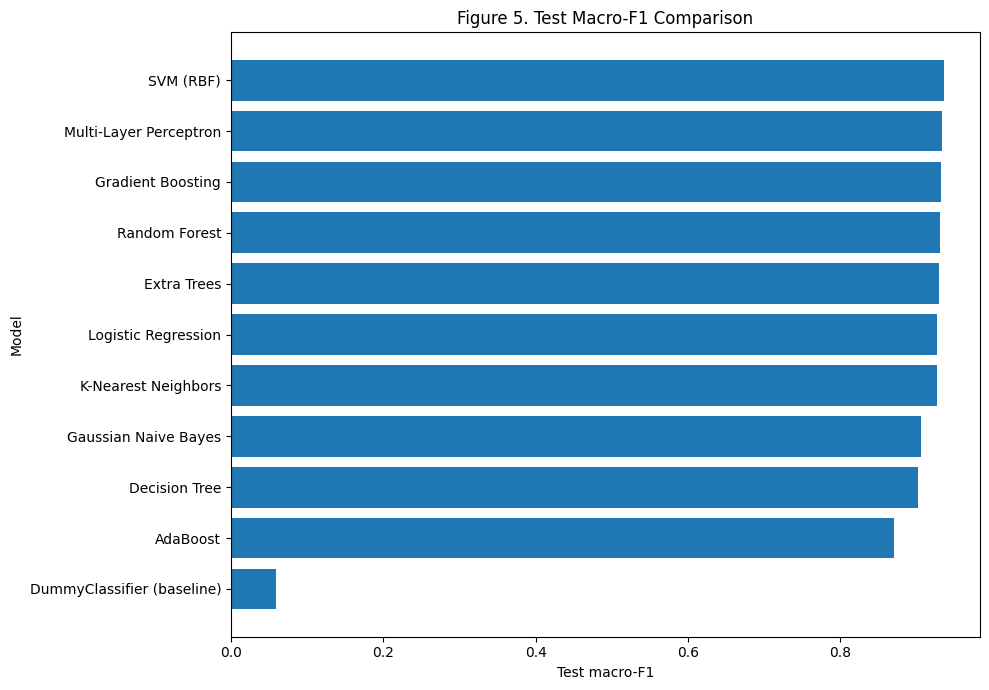

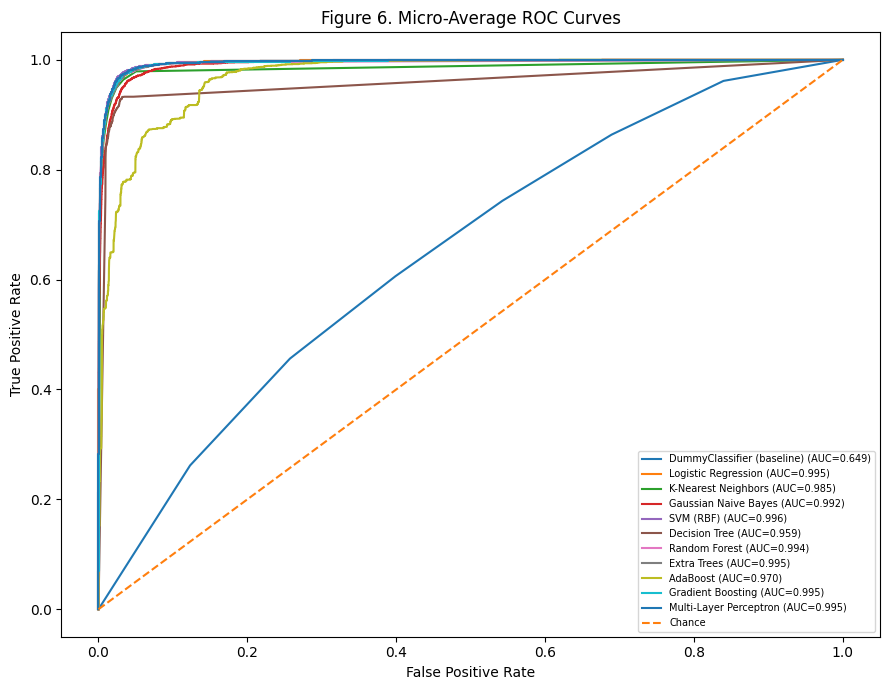

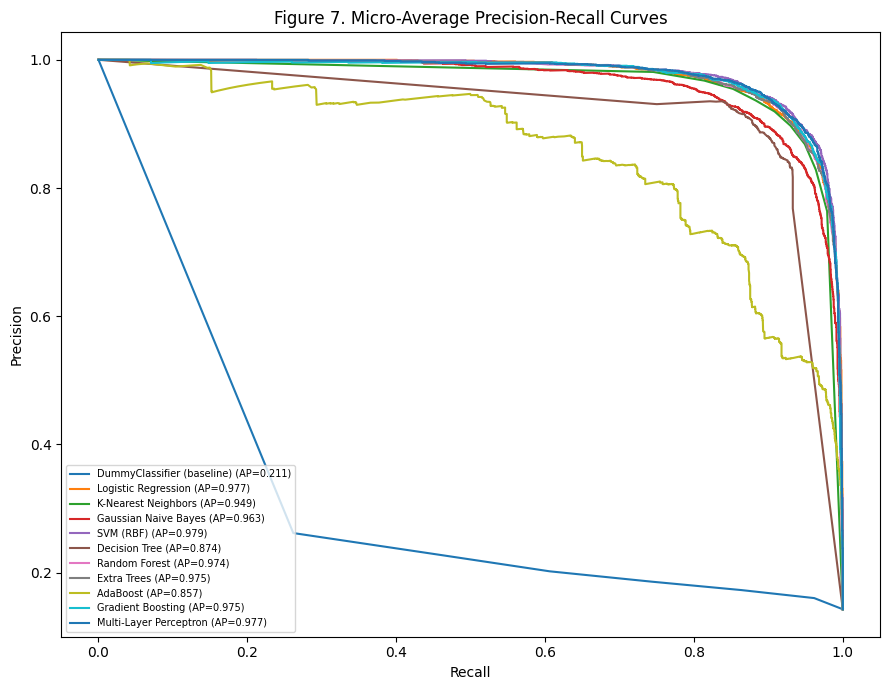

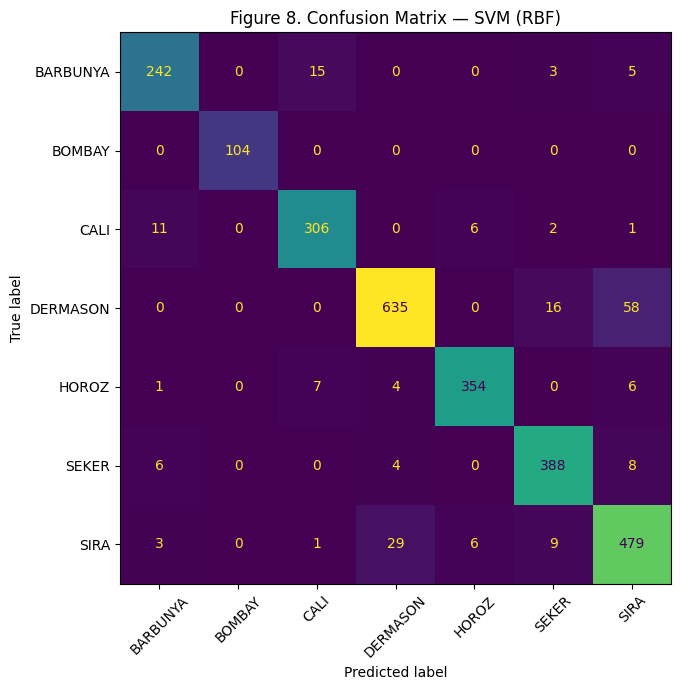

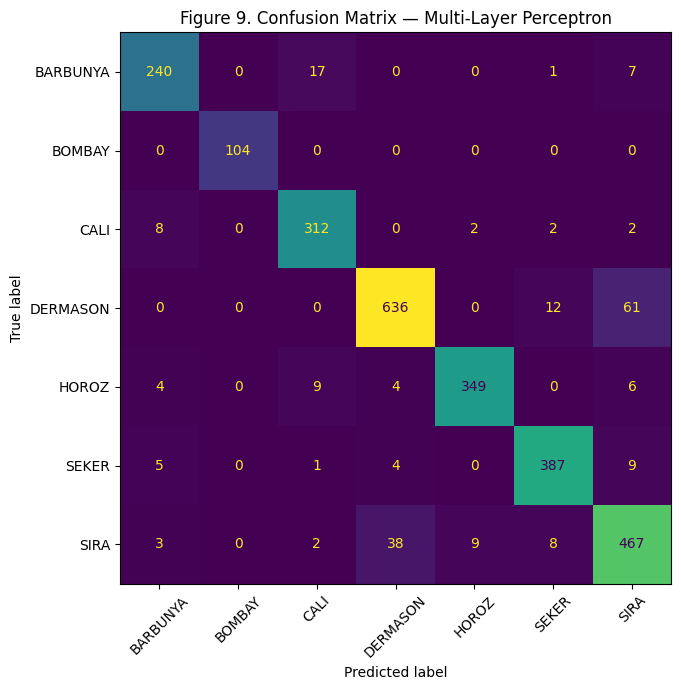

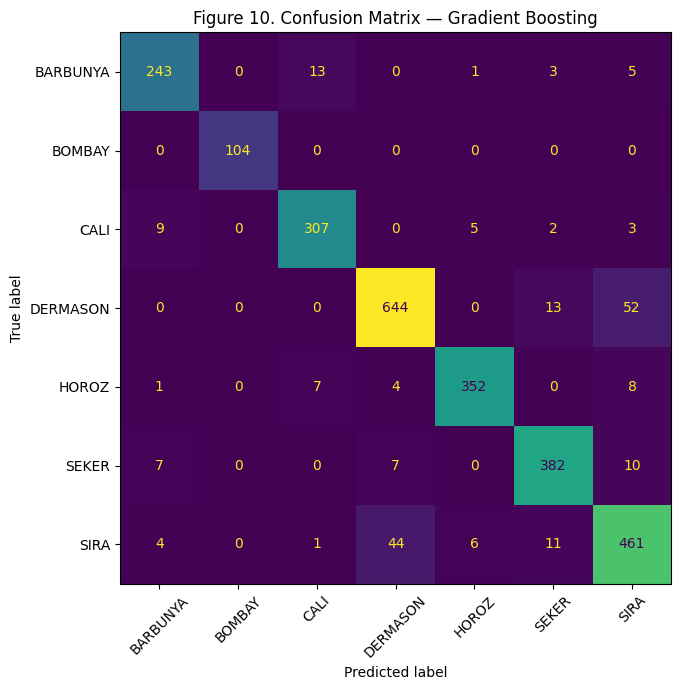

In [ ]:
# Figure 5: test macro-F1 comparison.
plot_results = all_results_df.sort_values("test_f1_macro", ascending=True)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_results["model"], plot_results["test_f1_macro"])
ax.set_xlabel("Test macro-F1")
ax.set_ylabel("Model")
ax.set_title("Figure 5. Test Macro-F1 Comparison")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure5_test_macro_f1_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Build aligned probability matrices for all models.
probabilities = {}
predictions = {}
estimators_for_plot = {"DummyClassifier (baseline)": baseline_fit}
estimators_for_plot.update(fitted_models)

for name, estimator in estimators_for_plot.items():
    predictions[name] = estimator.predict(X_test)
    raw_prob = estimator.predict_proba(X_test)
    estimator_classes = np.asarray(estimator.classes_)
    aligned = np.zeros((len(X_test), len(classes)))
    for j, class_label in enumerate(estimator_classes):
        aligned[:, np.where(classes == class_label)[0][0]] = raw_prob[:, j]
    probabilities[name] = aligned

# Figure 6: micro-average ROC curves for all models.
y_test_bin = label_binarize(y_test, classes=classes)
fig, ax = plt.subplots(figsize=(9, 7))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), prob.ravel())
    micro_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{name} (AUC={micro_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Figure 6. Micro-Average ROC Curves")
ax.legend(loc="lower right", fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "figure6_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 7: micro-average precision-recall curves for all models.
fig, ax = plt.subplots(figsize=(9, 7))
for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test_bin.ravel(), prob.ravel())
    micro_ap = average_precision_score(y_test_bin, prob, average="micro")
    ax.plot(recall, precision, label=f"{name} (AP={micro_ap:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Figure 7. Micro-Average Precision-Recall Curves")
ax.legend(loc="lower left", fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "figure7_precision_recall_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# Confusion matrices for the top three models ranked by held-out test macro-F1.
top_three = all_results_df[all_results_df["model"] != "DummyClassifier (baseline)"].head(3)["model"].tolist()
for rank, name in enumerate(top_three, start=1):
    cm = confusion_matrix(y_test, predictions[name], labels=classes)
    fig, ax = plt.subplots(figsize=(8, 7))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(f"Figure {7 + rank}. Confusion Matrix — {name}")
    fig.tight_layout()
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    fig.savefig(FIG_DIR / f"confusion_matrix_{rank}_{safe_name}.png",
                dpi=300, bbox_inches="tight")
    plt.show()

## 11. Statistical comparison: exact McNemar test



In [ ]:
ranked_by_cv = results_df.sort_values("best_cv_macro_f1_mean", ascending=False)
model_a_name = ranked_by_cv.iloc[0]["model"]
model_b_name = ranked_by_cv.iloc[1]["model"]

pred_a = predictions[model_a_name]
pred_b = predictions[model_b_name]
correct_a = (pred_a == y_test.to_numpy())
correct_b = (pred_b == y_test.to_numpy())

a_correct_b_wrong = int(np.sum(correct_a & ~correct_b))
a_wrong_b_correct = int(np.sum(~correct_a & correct_b))
discordant = a_correct_b_wrong + a_wrong_b_correct

if discordant == 0:
    mcnemar_stat = 0.0
    mcnemar_p = 1.0
else:
    mcnemar_stat = (
        (abs(a_correct_b_wrong - a_wrong_b_correct) - 1) ** 2
    ) / discordant
    mcnemar_p = binomtest(
        min(a_correct_b_wrong, a_wrong_b_correct),
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue

ALPHA = 0.05
print("Model A (highest training CV macro-F1):", model_a_name)
print("Model B (second-highest training CV macro-F1):", model_b_name)
print("A correct, B wrong:", a_correct_b_wrong)
print("A wrong, B correct:", a_wrong_b_correct)
print("Continuity-corrected McNemar statistic:", round(mcnemar_stat, 4))
print("Exact two-sided p-value:", mcnemar_p)
print("Significance level:", ALPHA)
print("Interpretation:",
      "Evidence of different error rates at alpha=0.05."
      if mcnemar_p < ALPHA else
      "No statistically significant difference in error rates at alpha=0.05.")

Model A (highest training CV macro-F1): Multi-Layer Perceptron
Model B (second-highest training CV macro-F1): SVM (RBF)
A correct, B wrong: 35
A wrong, B correct: 48
Continuity-corrected McNemar statistic: 1.7349
Exact two-sided p-value: 0.18745986796619285
Significance level: 0.05
Interpretation: No statistically significant difference in error rates at alpha=0.05.


## 12. Feature-selection effect



,feature_count,cv_macro_f1_mean,cv_macro_f1_std
0,12,0.9356,0.0082
1,16,0.9415,0.0057


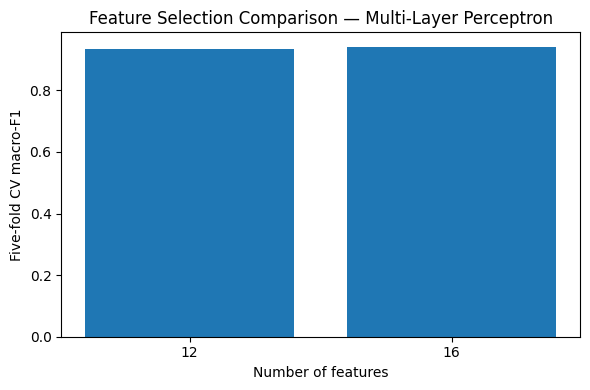

In [ ]:
best_model_name = ranked_by_cv.iloc[0]["model"]
best_model_pipeline = fitted_models[best_model_name]

feature_cv_rows = []
for k_value in [12, 16]:
    candidate = clone(best_model_pipeline)
    candidate.set_params(select__k=k_value)
    scores = cross_val_score(
        candidate, X_train, y_train,
        cv=cv, scoring="f1_macro",
        n_jobs=N_JOBS
    )
    feature_cv_rows.append({
        "feature_count": k_value,
        "cv_macro_f1_mean": scores.mean(),
        "cv_macro_f1_std": scores.std(ddof=1)
    })

feature_selection_df = pd.DataFrame(feature_cv_rows)
display(feature_selection_df.round(4))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    feature_selection_df["feature_count"].astype(str),
    feature_selection_df["cv_macro_f1_mean"]
)
ax.set_xlabel("Number of features")
ax.set_ylabel("Five-fold CV macro-F1")
ax.set_title(f"Feature Selection Comparison — {best_model_name}")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure8_feature_selection_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 13. Model interpretability: permutation importance



,feature,importance_mean,importance_std
10,roundness,0.173742,0.007736
4,AspectRation,0.131023,0.003826
12,ShapeFactor1,0.097117,0.004091
15,ShapeFactor4,0.090923,0.006048
13,ShapeFactor2,0.069986,0.005648
6,ConvexArea,0.063454,0.003969
0,Area,0.049115,0.002773
5,Eccentricity,0.046949,0.003706
9,Solidity,0.037781,0.003053
3,MinorAxisLength,0.029482,0.003135


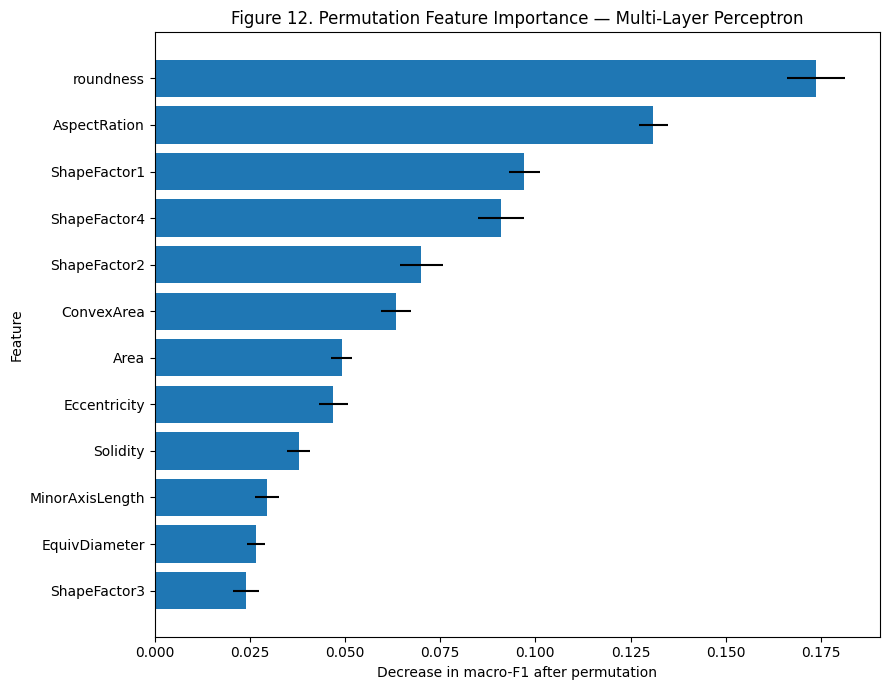

In [ ]:
best_estimator = fitted_models[best_model_name]

perm = permutation_importance(
    best_estimator,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df)

fig, ax = plt.subplots(figsize=(9, 7))
top_imp = importance_df.head(12).sort_values("importance_mean")
ax.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
ax.set_xlabel("Decrease in macro-F1 after permutation")
ax.set_ylabel("Feature")
ax.set_title(f"Figure 12. Permutation Feature Importance — {best_model_name}")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure9_permutation_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 14. Error analysis



In [ ]:
best_test_pred = predictions[best_model_name]
best_test_prob = probabilities[best_model_name]
confidence = best_test_prob.max(axis=1)

error_df = X_test.copy()
error_df["true_class"] = y_test.to_numpy()
error_df["predicted_class"] = best_test_pred
error_df["prediction_confidence"] = confidence
error_df["correct"] = best_test_pred == y_test.to_numpy()

misclassified_df = error_df.loc[~error_df["correct"]].sort_values(
    "prediction_confidence", ascending=False
)

print("Best model by training CV macro-F1:", best_model_name)
print("Misclassified test samples:", len(misclassified_df), "of", len(X_test))
print("Test error rate:", round(1 - accuracy_score(y_test, best_test_pred), 4))
display(misclassified_df.head(20))

# Most frequent true-class / predicted-class error pairs.
if len(misclassified_df):
    error_pairs = (
        misclassified_df.groupby(["true_class", "predicted_class"])
        .size().sort_values(ascending=False).head(15)
        .rename("count").reset_index()
    )
    display(error_pairs)
else:
    print("No test errors were observed for this model.")

Best model by training CV macro-F1: Multi-Layer Perceptron
Misclassified test samples: 214 of 2709
Test error rate: 0.079


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,true_class,predicted_class,prediction_confidence,correct
2591,68024,1011.261,380.569641,230.330448,1.652277,0.796054,69648,294.297208,0.699188,0.976683,0.835883,0.773307,0.005595,0.001234,0.598004,0.988068,BARBUNYA,CALI,0.999865,False
2021,56693,933.372,304.477400,237.533053,1.281832,0.625613,57737,268.670373,0.777426,0.981918,0.817767,0.882398,0.005371,0.002008,0.778627,0.998069,SEKER,BARBUNYA,0.999367,False
6702,56329,1019.436,359.427061,204.041941,1.761535,0.823245,58567,267.806479,0.646813,0.961787,0.681117,0.745093,0.006381,0.001213,0.555163,0.977939,HOROZ,BARBUNYA,0.999105,False
1844,46427,811.657,293.918029,202.246160,1.453269,0.725612,46974,243.131019,0.683796,0.988355,0.885596,0.827207,0.006331,0.001828,0.684271,0.994430,SEKER,SIRA,0.998761,False
2822,71940,1033.770,399.303050,230.492825,1.732388,0.816576,72706,302.649720,0.768959,0.989464,0.845926,0.757945,0.005551,0.001130,0.574481,0.995223,BARBUNYA,CALI,0.998394,False
2048,48160,829.234,304.528282,202.715513,1.502245,0.746246,48950,247.627172,0.754043,0.983861,0.880121,0.813150,0.006323,0.001705,0.661213,0.993304,BARBUNYA,SIRA,0.998313,False
3872,45666,789.770,274.863357,211.885139,1.297228,0.636987,46074,241.130166,0.748378,0.991145,0.920029,0.877273,0.006019,0.002199,0.769608,0.998357,CALI,SEKER,0.997534,False
2619,68451,1002.041,384.893598,228.071206,1.687603,0.805529,69370,295.219444,0.720234,0.986752,0.856680,0.767016,0.005623,0.001200,0.588313,0.992839,BARBUNYA,CALI,0.997407,False
8418,43403,813.743,325.482876,172.905642,1.882431,0.847229,44425,235.079595,0.810922,0.976995,0.823673,0.722249,0.007499,0.001259,0.521643,0.981957,SIRA,HOROZ,0.996363,False
13533,42042,771.515,288.082674,186.347090,1.545947,0.762615,42476,231.364511,0.816254,0.989782,0.887574,0.803118,0.006852,0.001758,0.644999,0.997134,DERMASON,SIRA,0.991261,False


,true_class,predicted_class,count
0,DERMASON,SIRA,61
1,SIRA,DERMASON,38
2,BARBUNYA,CALI,17
3,DERMASON,SEKER,12
4,HOROZ,CALI,9
5,SEKER,SIRA,9
6,SIRA,HOROZ,9
7,CALI,BARBUNYA,8
8,SIRA,SEKER,8
9,BARBUNYA,SIRA,7


## 15. Classification report for the selected model

In [ ]:
best_report = classification_report(
    y_test, best_test_pred,
    labels=classes,
    output_dict=True,
    zero_division=0
)
best_report_df = pd.DataFrame(best_report).T
display(best_report_df.round(4))

,precision,recall,f1-score,support
BARBUNYA,0.9231,0.9057,0.9143,265.000
BOMBAY,1.0000,1.0000,1.0000,104.000
CALI,0.9150,0.9571,0.9355,326.000
DERMASON,0.9326,0.8970,0.9145,709.000
HOROZ,0.9694,0.9382,0.9536,372.000
SEKER,0.9439,0.9532,0.9485,406.000
SIRA,0.8460,0.8861,0.8656,527.000
accuracy,0.9210,0.9210,0.9210,0.921
macro avg,0.9328,0.9339,0.9331,2709.000
weighted avg,0.9220,0.9210,0.9212,2709.000


## 16. Save all results, figures, settings and reproducibility information



In [ ]:
# Save result tables.
all_results_df.to_csv(TABLE_DIR / "model_comparison_all_metrics.csv", index=False)
results_df.to_csv(TABLE_DIR / "ten_model_results.csv", index=False)
feature_selection_df.to_csv(TABLE_DIR / "feature_selection_comparison.csv", index=False)
importance_df.to_csv(TABLE_DIR / "permutation_feature_importance.csv", index=False)
best_report_df.to_csv(TABLE_DIR / "best_model_classification_report.csv")
misclassified_df.to_csv(TABLE_DIR / "misclassified_test_samples.csv", index=False)

# Save best parameters.
with open(TABLE_DIR / "best_hyperparameters.json", "w") as f:
    json.dump(best_params_dict, f, indent=2, default=str)

search_space_rows = []
for model_name, config in MODEL_CONFIGS.items():
    search_space_rows.append({
        "model": model_name,
        "family": config["family"],
        "imbalance_handling": "SMOTE inside training folds" if config["use_smote"] else "balanced class weights",
        "search_space": json.dumps(config["params"], default=str),
        "best_parameters": json.dumps(best_params_dict[model_name], default=str)
    })
pd.DataFrame(search_space_rows).to_csv(TABLE_DIR / "search_spaces_and_best_parameters.csv", index=False)

# Save basic EDA summaries for the report.
target_counts.rename("samples").to_csv(TABLE_DIR / "class_distribution.csv")
corr.to_csv(TABLE_DIR / "feature_correlation_matrix.csv")

# Save selected model and metadata.
import joblib
joblib.dump(best_estimator, MODEL_DIR / "best_dry_bean_model.joblib")

metadata = {
    "dataset_file": str(DATA_PATH),
    "original_rows": int(original_rows),
    "rows_after_duplicate_removal": int(len(df_clean)),
    "duplicates_removed": int(removed_duplicates),
    "feature_count": int(len(numeric_cols)),
    "class_count": int(df_clean["Class"].nunique()),
    "target": "Class",
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "cv_folds": CV_SPLITS,
    "random_search_iterations_per_model": N_ITER,
    "selection_metric": "macro_f1",
    "best_model_by_training_cv_macro_f1": best_model_name,
    "best_model_cv_macro_f1_mean": float(
        results_df.loc[results_df["model"] == best_model_name,
                       "best_cv_macro_f1_mean"].iloc[0]
    ),
    "alpha": ALPHA,
    "mcnemar_model_a": model_a_name,
    "mcnemar_model_b": model_b_name,
    "mcnemar_exact_p_value": float(mcnemar_p),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__
}

with open(RESULTS_DIR / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved results to:", RESULTS_DIR.resolve())
print("Best model by training CV macro-F1:", best_model_name)

Saved results to: /content/dry_bean_results
Best model by training CV macro-F1: Multi-Layer Perceptron


## 17. Final summary for the report



In [ ]:
summary_cols = [
    "model", "best_cv_macro_f1_mean", "best_cv_macro_f1_std",
    "test_accuracy", "test_precision_macro", "test_precision_weighted",
    "test_recall_macro", "test_recall_weighted",
    "test_f1_macro", "test_f1_weighted", "test_balanced_accuracy",
    "test_mcc", "test_roc_auc_ovr_macro", "test_pr_auc_macro",
    "final_refit_time_sec", "inference_ms_per_sample"
]
display(all_results_df[summary_cols].round(4))

best_row = results_df.loc[results_df["model"] == best_model_name].iloc[0]
print("\nREPORTING SUMMARY")
print(f"Best model by CV macro-F1: {best_model_name}")
print(f"CV macro-F1: {best_row['best_cv_macro_f1_mean']:.4f} ± {best_row['best_cv_macro_f1_std']:.4f}")
print(f"Test accuracy: {best_row['test_accuracy']:.4f}")
print(f"Test macro-F1: {best_row['test_f1_macro']:.4f}")
print(f"Test weighted-F1: {best_row['test_f1_weighted']:.4f}")
print(f"Test macro ROC-AUC (OvR): {best_row['test_roc_auc_ovr_macro']:.4f}")
print(f"Test macro PR-AUC: {best_row['test_pr_auc_macro']:.4f}")
print(f"Training refit time (sec): {best_row['final_refit_time_sec']:.2f}")
print(f"Inference time (ms/sample): {best_row['inference_ms_per_sample']:.4f}")
print(f"McNemar exact p-value: {mcnemar_p:.6g}")

,model,best_cv_macro_f1_mean,best_cv_macro_f1_std,test_accuracy,test_precision_macro,test_precision_weighted,test_recall_macro,test_recall_weighted,test_f1_macro,test_f1_weighted,test_balanced_accuracy,test_mcc,test_roc_auc_ovr_macro,test_pr_auc_macro,final_refit_time_sec,inference_ms_per_sample
0,SVM (RBF),0.9401,0.0064,0.9258,0.9358,0.9269,0.9377,0.9258,0.9365,0.9260,0.9377,0.9106,0.9945,0.9785,5.3130,0.1521
1,Multi-Layer Perceptron,0.9415,0.0051,0.9210,0.9328,0.9220,0.9339,0.9210,0.9331,0.9212,0.9339,0.9047,0.9946,0.9781,27.9751,0.0025
2,Gradient Boosting,0.9377,0.0056,0.9203,0.9328,0.9207,0.9327,0.9203,0.9327,0.9204,0.9327,0.9036,0.9936,0.9751,92.4153,0.0112
3,Random Forest,0.9358,0.0059,0.9192,0.9323,0.9193,0.9294,0.9192,0.9308,0.9191,0.9294,0.9022,0.9925,0.9745,7.9399,0.0169
4,Extra Trees,0.9321,0.0054,0.9195,0.9319,0.9199,0.9286,0.9195,0.9300,0.9196,0.9286,0.9026,0.9934,0.9757,1.9460,0.0228
5,Logistic Regression,0.9338,0.0053,0.9147,0.9259,0.9162,0.9290,0.9147,0.9271,0.9150,0.9290,0.8973,0.9945,0.9774,1.9263,0.0016
6,K-Nearest Neighbors,0.9300,0.0062,0.9140,0.9265,0.9152,0.9266,0.9140,0.9262,0.9142,0.9266,0.8962,0.9848,0.9520,1.2884,0.3810
7,Gaussian Naive Bayes,0.9063,0.0059,0.8959,0.9071,0.8986,0.9077,0.8959,0.9065,0.8962,0.9077,0.8749,0.9912,0.9626,1.1376,0.0018
8,Decision Tree,0.9165,0.0073,0.8893,0.9010,0.8902,0.9041,0.8893,0.9023,0.8895,0.9041,0.8663,0.9613,0.8875,1.3765,0.0012
9,AdaBoost,0.8700,0.0417,0.8638,0.8755,0.8682,0.8705,0.8638,0.8705,0.8637,0.8705,0.8361,0.9620,0.8491,17.8548,0.0591



REPORTING SUMMARY
Best model by CV macro-F1: Multi-Layer Perceptron
CV macro-F1: 0.9415 ± 0.0051
Test accuracy: 0.9210
Test macro-F1: 0.9331
Test weighted-F1: 0.9212
Test macro ROC-AUC (OvR): 0.9946
Test macro PR-AUC: 0.9781
Training refit time (sec): 27.98
Inference time (ms/sample): 0.0025
McNemar exact p-value: 0.18746


## 18. Package the outputs for download



In [ ]:
zip_path = Path("dry_bean_results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in RESULTS_DIR.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.relative_to(RESULTS_DIR.parent))

print("Created:", zip_path.resolve())
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Outside Colab: download the ZIP from the notebook working directory.")

Created: /content/dry_bean_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>